# 04 Exploratory Analysis

This notebook corresponds to the **Exploratory Data Analysis / Descriptive Data Mining** stage.

Goals:
- visualise temporal usage patterns
- inspect rolling behaviour for individual stations
- rank stations by fluctuation and imbalance
- compare central vs peripheral stations

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker

PROJECT_ROOT = Path('..').resolve()
FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features.parquet'
if not FEATURES_PATH.exists():
    FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features.csv.gz'

if FEATURES_PATH.suffix == '.parquet':
    df = pd.read_parquet(FEATURES_PATH)
else:
    df = pd.read_csv(FEATURES_PATH)

df['last_reported'] = pd.to_datetime(df['last_reported'], errors='coerce')
print(df.shape)
df.head()

(13513883, 13)


,station_id,last_reported,hour_slot,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,utilisation,dock_ratio,empty_risk,full_risk,center_index,area_type_str
0,1,2022-04-27 13:00:02,13,2,True,0.0,0.0,0.0,0.870968,True,False,1,retail
1,1,2022-04-27 13:30:02,13,2,True,0.0,0.0,0.0,0.870968,True,False,1,retail
2,1,2022-04-27 14:00:02,14,2,True,0.0,0.0,0.0,0.870968,True,False,1,retail
3,1,2022-04-27 14:30:02,14,2,True,0.0,0.0,0.0,0.000000,True,False,1,retail
4,1,2022-04-27 15:00:02,15,2,True,0.0,0.0,0.0,0.000000,True,False,1,retail


## System-level heatmap: weekday × hour

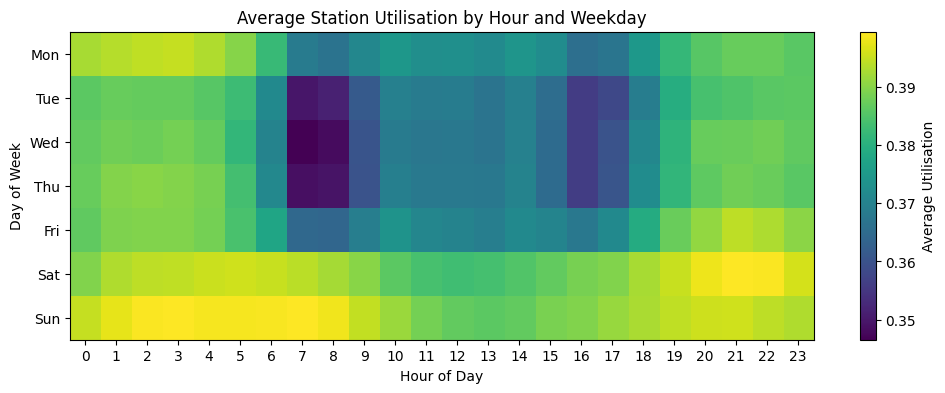

In [2]:
heatmap_data = (
    df.groupby(['days_of_week', 'hour_slot'])['utilisation']
      .mean()
      .unstack()
)
heatmap_data.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

plt.figure(figsize=(12,4))
plt.imshow(heatmap_data, aspect='auto', cmap='viridis')
plt.colorbar(label='Average Utilisation')
plt.xticks(range(24), range(24))
plt.yticks(range(7), heatmap_data.index)
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.title('Average Station Utilisation by Hour and Weekday')
plt.show()

## Fluctuation ranking across stations

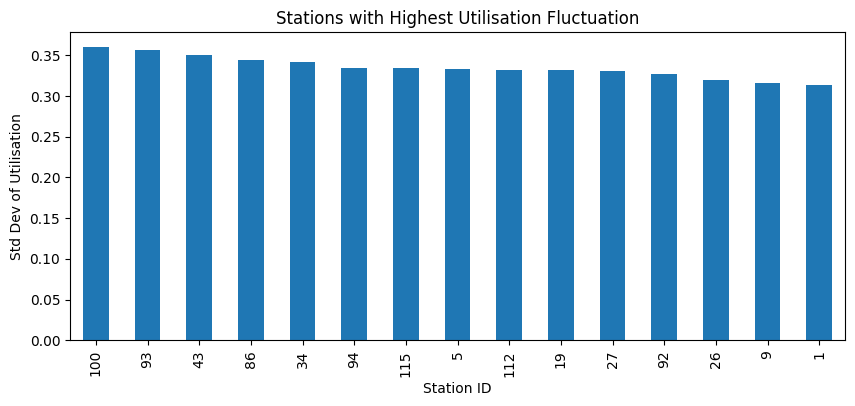

In [3]:
station_fluctuation = (
    df.groupby('station_id')['utilisation']
      .std()
      .sort_values(ascending=False)
)

station_fluctuation.head(15).plot(kind='bar', figsize=(10,4))
plt.title('Stations with Highest Utilisation Fluctuation')
plt.ylabel('Std Dev of Utilisation')
plt.xlabel('Station ID')
plt.show()

## Empty station ranking

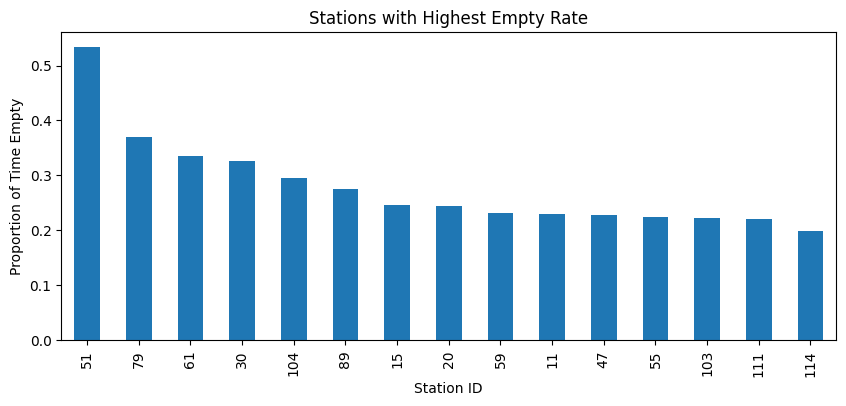

In [4]:
df['empty_station'] = df['utilisation'] == 0
empty_rate = (
    df.groupby('station_id')['empty_station']
      .mean()
      .sort_values(ascending=False)
)

empty_rate.head(15).plot(kind='bar', figsize=(10,4))
plt.title('Stations with Highest Empty Rate')
plt.ylabel('Proportion of Time Empty')
plt.xlabel('Station ID')
plt.show()

## Weekly rolling view for one station

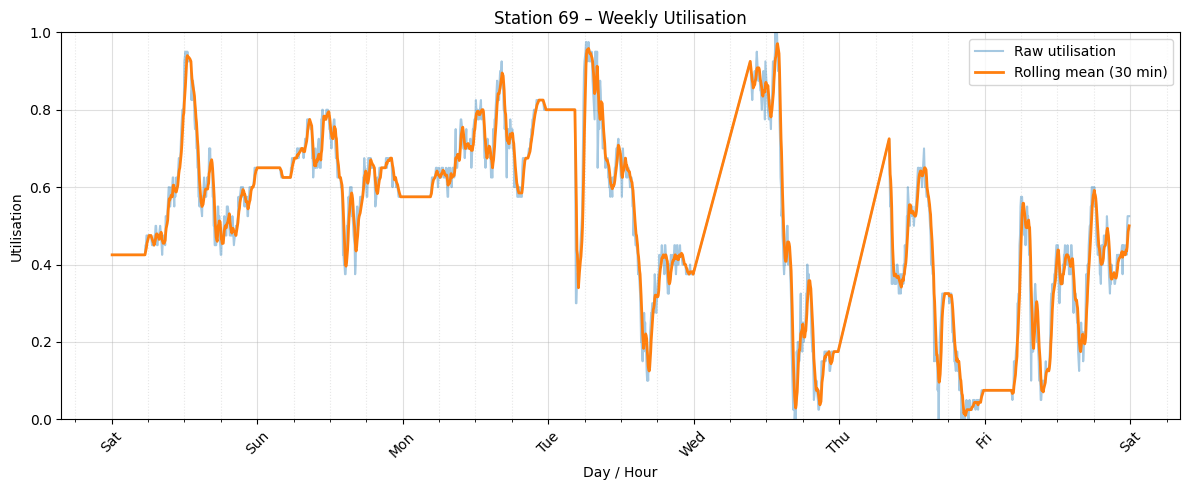

In [5]:
# station_id = int(df['station_id'].mode().iloc[0]) # most common station

station_id = 69   # choose the station you want to analyze
start = pd.Timestamp('2024-06-01')
end   = pd.Timestamp('2024-06-08')

station_df = df[
    (df['station_id'] == station_id) &
    (df['last_reported'] >= start) &
    (df['last_reported'] < end)
].sort_values('last_reported')

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(station_df['last_reported'], station_df['utilisation'], alpha=0.4, label='Raw utilisation')
ax.plot(station_df['last_reported'], station_df['roll_mean_30min'], linewidth=2, label='Rolling mean (30 min)')

ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[0,6,12,18]))
ax.grid(True, which='major', linewidth=0.8, alpha=0.4)
ax.grid(True, which='minor', linestyle=':', alpha=0.3)

ax.set_ylim(0, 1.0)
ax.set_title(f'Station {station_id} – Weekly Utilisation')
ax.set_xlabel('Day / Hour')
ax.set_ylabel('Utilisation')
ax.legend()
plt.setp(ax.get_xticklabels(), rotation=45)
plt.tight_layout()
plt.show()

## Central vs peripheral comparison

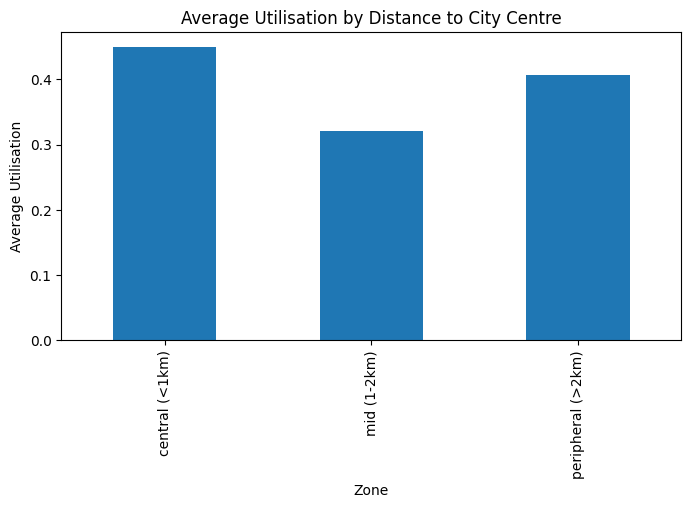

In [6]:
zone_util = df.groupby('center_index')['utilisation'].mean()
zone_util.index = ['central (<1km)', 'mid (1-2km)', 'peripheral (>2km)']
zone_util.plot(kind='bar', figsize=(8,4))
plt.title('Average Utilisation by Distance to City Centre')
plt.ylabel('Average Utilisation')
plt.xlabel('Zone')
plt.show()

## Boxplot by hour

<Figure size 1000x500 with 0 Axes>

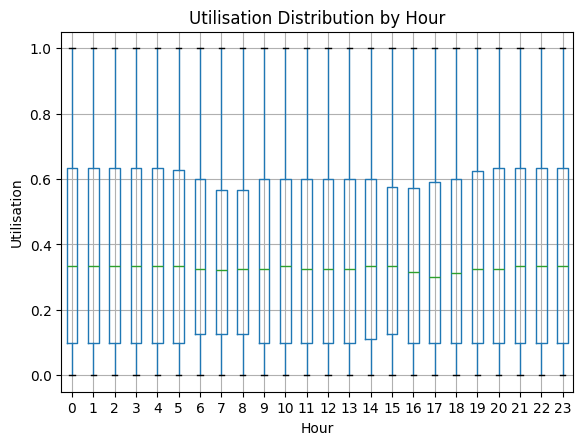

In [7]:
plt.figure(figsize=(10,5))
df.boxplot(column='utilisation', by='hour_slot')
plt.title('Utilisation Distribution by Hour')
plt.suptitle('')
plt.xlabel('Hour')
plt.ylabel('Utilisation')
plt.show()

## Notes

This notebook should remain focused on **analysis and interpretation**, not on data cleaning. Any new reusable feature should normally be added back to the feature-engineering notebook.